# Assignment 6: Lighting Estimation

MIDS W281: Computer Vision

## Recommended Libraries

In [ ]:
from scipy.io import loadmat
import numpy as np
import matplotlib.pyplot as plt

![Hybrid Teaser](https://raw.githubusercontent.com/W281/fileRepository/main/Assignments/Assignment_6/sphere.png)

 ### Overview
Lighting estimation is critical for many computer vision applications, and demonstrates a common use of least squares operations on pixel values. Accurate estimation of the lighting environment under which an image was captured can be used for image forensics, image re-lighting, 3D surface modeling, and compositing images with rendered objects, and many other techniques. For this assignment we will compute the lighting direction for a simple toy problem consisting of a sphere with faceted edges.

Consider the illuminated sphere shown above. If, as in this case, the light illuminating the sphere is distant and the sphere is a Lambertian surface, the amount of light $I$ that strikes any point ($X,Y,Z$) on the sphere's surface is equal to the dot product between the 3-D surface normal $N$ at ($X,Y,Z$) and the single 3-D vector $L$ which specifies the direction to the light source. In this assignment, you will estimate the direction to the light $L$ using least squares. You can assume that there is only one light source in the scene and there is no ambient light.

### Description

1. Write a Python code to load the given 3-D [$X$-](X.npy), [$Y$-](Y.npy), and [$Z$-](Z.npy) coordinates of the sphere and the corresponding illumination [$I$](I.npy). After loading the files you will have four 41 x 41 matrices corresponding to the illumination $I$ and the $X$-, $Y$-, and $Z$- coordinates of the sphere. That is, for any $u$ and $v$ between 1 and 41, the illumination on the sphere's surface at ($X_{u,v},Y_{u,v},Z_{u,v}$) is $I_{u,v}$. Display this sphere using the `plot_surface` method in Python. Set the color values so that the displayed sphere looks like the above image without the $L$ and $N$ arrows.  
&nbsp;

2. For each ($X,Y,Z$) on the sphere's surface, determine the surface normal $N$. The surface normal at any point on the sphere is a vector from the sphere origin to the point. Since the sphere is centered at the origin, this is a simple calculation. The surface normal should be specified as a unit vector.  
&nbsp;  

3. Using least-squares, estimate the lighting (a 3-D vector). Your solution should create an over constrained system of linear equations in the surface normal and illumination at each point ($X,Y,Z$) on the sphere's surface that is not in shadow (i.e. intensity is greater than zero). Your solution for the light vector $L$ is determined by solving this system of linear equations using least-squares.   
&nbsp;

**Do not use pseudo inverse functions like `numpy.linalg.pinv` or least squares functions `numpy.linalg.lstsq`.**

**You are able to use `numpy.linalg.inv`**

### Deliverables:

- Python code for computing the sphere normals and the light direction
- A plot displaying the 3-D sphere
- The 3-D direction of the light source

#### Create your functions

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: enables 3D projection

def plot_save_sphere(X, Y, Z, C, out_file):
    # normalize colors to [0,1] for facecolors (illumination may exceed 1)
    C = np.asarray(C, dtype=float)
    if C.max() > 0:
        C = C / C.max()
    C = np.clip(C, 0, 1)

    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(X, Y, Z, facecolors=C, rstride=1, cstride=1,
                    linewidth=0, antialiased=False, shade=False)
    ax.set_box_aspect((1, 1, 1))   # equal aspect so it looks like a sphere

    plt.title('Plot the Sphere')
    plt.tight_layout(pad=5.08, h_pad=None, w_pad=None, rect=None)
    plt.savefig(out_file, bbox_inches='tight')
    plt.show()

def compute_normals(X, Y, Z):
    # vectorize inputs (41,41) -> (41*41, 1)
    x = X.reshape(-1, 1)
    y = Y.reshape(-1, 1)
    z = Z.reshape(-1, 1)

    # normal at each point = the point itself (sphere centered at origin)
    N = np.concatenate([x, y, z], axis=1).astype(float)   # (1681, 3)

    # 2-norm of each normal
    norm = np.sqrt((N ** 2).sum(axis=1, keepdims=True))
    norm[norm == 0] = 1.0

    # unit normals
    N = N / norm
    return N

#### Run your code

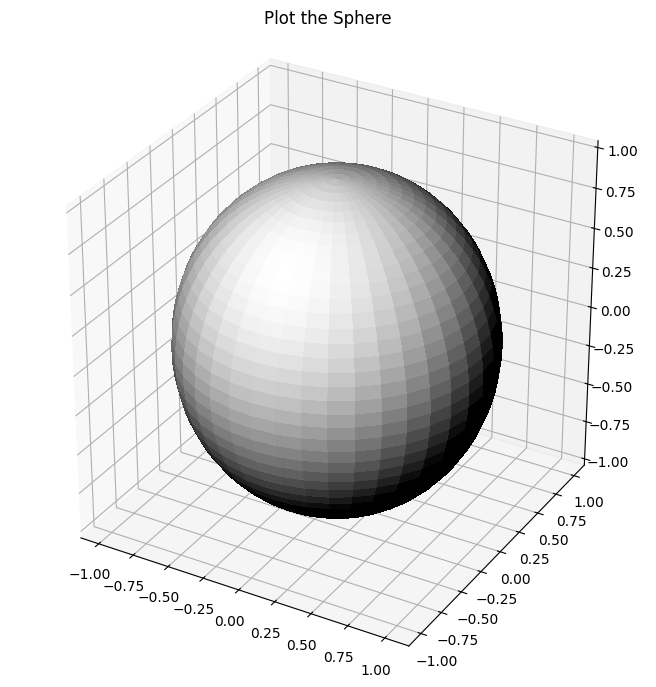

In [ ]:
# load the npy and plot the sphere
X = np.load('X.npy')
Y = np.load('Y.npy')
Z = np.load('Z.npy')
I = np.load('I.npy')

# plot the sphere
plot_save_sphere(X,Y,Z, np.concatenate((I[:,:,np.newaxis],
                                        I[:,:,np.newaxis],
                                        I[:,:,np.newaxis]), axis=2), 'temp.png')


N = compute_normals(X,Y,Z)

#### Calculate and print the 3D direction of light source

In [ ]:
# calculate light direction using least squares
N = compute_normals(X, Y, Z)

# vectorize I and keep only points that are not in shadow (intensity > 0)
I_vec = I.reshape(-1)
mask = I_vec > 0
A = N[mask]        # surface normals of lit points
b = I_vec[mask]    # their illumination

# solve I = N . l  via the normal equations: l = (A^T A)^-1 A^T b
l = np.linalg.inv(A.T @ A) @ (A.T @ b)

print('Light direction L:', l)
print('Unit direction:   ', l / np.linalg.norm(l))

Light direction L: [ 0.00596716 -0.70706699  0.70705375]
Unit direction:    [ 0.00596745 -0.70710081  0.70708757]
